## Milestone 1: represent and check the system.

this first snippet of code aim to run a tests for small configurations. The result is compared against the calculation done by hand. We descided to run total of 4 tests.

**Tests**
- 5x5 lattice initialisation testing: create a 5x5 random and ordered (all 1 or -1) lattice (matrix) and print it.
- 3x3 lattice testing: compared the hand calculated E (total energy), e (energy per spin), M (total magnetism), m (magnetization per spin) for [[ 1,  1, -1], [ 1, -1, -1], [-1, -1,  1]] lattice.
- 4x4 ordered lattice testing: simmilar to previous test, compared the hand calculated E, e, M, m against computed ones for 4x4 ordered lattice ( all up or down)
- energy change calculation: 

**Functions**

In this code we mainly used 5 main supporting function we created in supporting_function.py here is the brief break down of what each function does.

| Function    | What it does |
| -------- | ------- |
| make_lattice (L, mode = "random")| create a LxL matrix, you can set the mode to either "random", "up", or "down". "random" generates random lattice and "up" and "down" you can generate ordered lattice. |
| calc_E_e(lattice, J=1.0, h=0.0) | calculates the E and e of your LxL lattice. |
| calc_M_m(lattice) | calculates the M and m of your LxL lattice. |
| calc_flip_E (lattice, i, j, J=1.0, h=0.0) | apply periodic boundary and calculates the neighbor sum and outputs the Energy changed from flipping. |

*all details to function are in supporting_function.py

**Example Calculation**

Example calculation for 2x2 lattice

$$
lattice = \begin{bmatrix} +1 & +1 & -1 \\ +1 & -1 & -1 \\ -1 & -1 & +1 \end{bmatrix}
$$




In [1]:
import supporting_function as sf
import numpy as np

#------- testing 5x5 lattice initialization -------

rand_lattice = sf.make_lattice(5, mode = "random")
print("------- random lattice -------")
print(f"Random lattice:\n{rand_lattice}\n")

ordered_up_lattice = sf.make_lattice(5, mode = "up")
print("------- ordered up lattice -------")
print(f"Ordered up lattice:\n{ordered_up_lattice}\n")

#------- 3x3 lattice testing -------

test_lattice = np.array([[ 1,  1, -1], [ 1, -1, -1], [-1, -1,  1]])

E, e = sf.calc_E_e(test_lattice)
M, m = sf.calc_M_m(test_lattice)

#calculation is on note.md
print("------- 3x3 lattice test-------")
print(f"Total Energy: {E} (expected: 6.0)")
print(f"Energy per spin: {e} (expected: 0.6667)")
print(f"Total Magnetism: {M} (expected: -1.0)")
print(f"Magnetization per spin: {m} (expected: -0.1111)\n")

#------- 4x4 ordered lattice test -------

up_lattice  = sf.make_lattice(4, mode = "up")
down_lattice = sf.make_lattice(4, mode = "down")

E_up, e_up = sf.calc_E_e(up_lattice)
E_down, e_down = sf.calc_E_e(down_lattice)

M_up, m_up = sf.calc_M_m(up_lattice)
M_down, m_down = sf.calc_M_m(down_lattice)

print("------- up lattice test-------")
print(f"Total Energy: {E_up} (expected: -32.0), Energy per spin: {e_up} (expected: -2.0) ")
print(f"Total Magnetism: {M_up} (expected: 16.0), Magnetization per spin: {m_up} (expected: 1.0)\n")

print("------- down lattice test-------")
print(f"Total Energy: {E_down} (expected: -32.0), Energy per spin: {e_down} (expected: -2.0) ")
print(f"Total Magnetism: {M_down} (expected: -16.0), Magnetization per spin: {m_down} (expected: -1.0)\n")

#------- testing if the energy change calculation is correct ------

rand_lattice = sf.make_lattice(5, mode = "random")
E_initial, e_initial = sf.calc_E_e(rand_lattice)
Matched = True

test_position = [(0,0),(4,4),(0,4),(4,0),(0,2),(4,2),(2,0),(2,4),(2,2)]

print("------- testing energy change calculation after flipping spins -------")
for r, c in test_position:
    flip_E = sf.calc_flip_E(rand_lattice, r, c)

    flipped_grid = rand_lattice.copy()
    flipped_grid[r, c] *= -1
    E_flipped, e_flipped = sf.calc_E_e(flipped_grid)
    print (f"Flipping spin at position ({r}, {c}): calculated energy change: {flip_E}, expected energy change: {E_flipped - E_initial}")
    if flip_E != (E_flipped - E_initial):
        Matched = False
        
print("\n")
if Matched:
    print("All energy change calculations are correct!")
else:
    print("Some energy change calculations are incorrect!")

------- random lattice -------
Random lattice:
[[-1  1 -1 -1 -1]
 [-1 -1  1  1 -1]
 [-1  1 -1 -1  1]
 [ 1  1  1  1 -1]
 [-1 -1 -1  1  1]]

------- ordered up lattice -------
Ordered up lattice:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

------- 3x3 lattice test-------
Total Energy: 6.0 (expected: 6.0)
Energy per spin: 0.6666666666666666 (expected: 0.6667)
Total Magnetism: -1 (expected: -1.0)
Magnetization per spin: -0.1111111111111111 (expected: -0.1111)

------- up lattice test-------
Total Energy: -32.0 (expected: -32.0), Energy per spin: -2.0 (expected: -2.0) 
Total Magnetism: 16 (expected: 16.0), Magnetization per spin: 1.0 (expected: 1.0)

------- down lattice test-------
Total Energy: -32.0 (expected: -32.0), Energy per spin: -2.0 (expected: -2.0) 
Total Magnetism: -16 (expected: -16.0), Magnetization per spin: -1.0 (expected: -1.0)

------- testing energy change calculation after flipping spins -------
Flipping spin at position (0, 0): calculated energy c

## Milestone 2: generate and analyse trajectories.

**Tests**
- 5x5 lattice initialisation testing: create a 5x5 random and ordered (all 1 or -1) lattice (matrix) and print it.
- 3x3 lattice testing: compared the hand calculated E (total energy), e (energy per spin), M (total magnetism), m (magnetization per spin) for [[ 1,  1, -1], [ 1, -1, -1], [-1, -1,  1]] lattice.
- 4x4 ordered lattice testing: simmilar to previous test, compared the hand calculated E, e, M, m against computed ones for 4x4 ordered lattice ( all up or down)
- energy change calculation: 

**Functions**
| Function    | What it does |
| -------- | ------- |
| def run_sweep(s, T, num_sweeps, J=1.0, h=0.0) | run montecarlo testing num_sweep times |


- Implement the updates and produce trajectories of e(t) and m(t) from different initial configurations, together
with snapshots of the states reached after long runs.
- Produce the required 5,000-sweep trajectory at T = 1 K.
- Obtain preliminary temperature scans and calculate equilibrium means and variances, including initial estimates
of c and χ.
- Discuss your choice of equilibration and measurement periods, the interpretation of your results, and a practical
plan for completing the final figures and uncertainty estimates.

------- Initial lattice -------
[[ 1 -1 -1 -1 -1  1 -1  1 -1 -1]
 [ 1 -1  1 -1  1  1 -1 -1 -1 -1]
 [-1 -1 -1  1  1  1 -1  1 -1  1]
 [ 1  1 -1  1 -1 -1 -1  1  1  1]
 [ 1 -1  1 -1  1 -1  1  1  1 -1]
 [-1 -1  1  1  1 -1  1  1 -1  1]
 [ 1 -1 -1 -1 -1  1 -1 -1  1 -1]
 [-1 -1 -1  1 -1 -1  1 -1  1 -1]
 [ 1  1  1  1  1 -1 -1 -1 -1 -1]
 [-1  1  1  1 -1 -1 -1  1  1  1]]


------- Starting Monte Carlo sweep -------


------- Final lattice after Monte Carlo sweep -------


Final lattice after 1 Monte Carlo sweep:
 [[1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]]


------- Final Energy and Magnetism after Monte Carlo sweep -------


Total Energy:  -200.0
Energy per spin:  -2.0
Total Magnetism:  100
Magnetization per spin:  1.0


------- c and chi after Monte Carlo sweep -------
------- Plotting Magnetization and Energy 

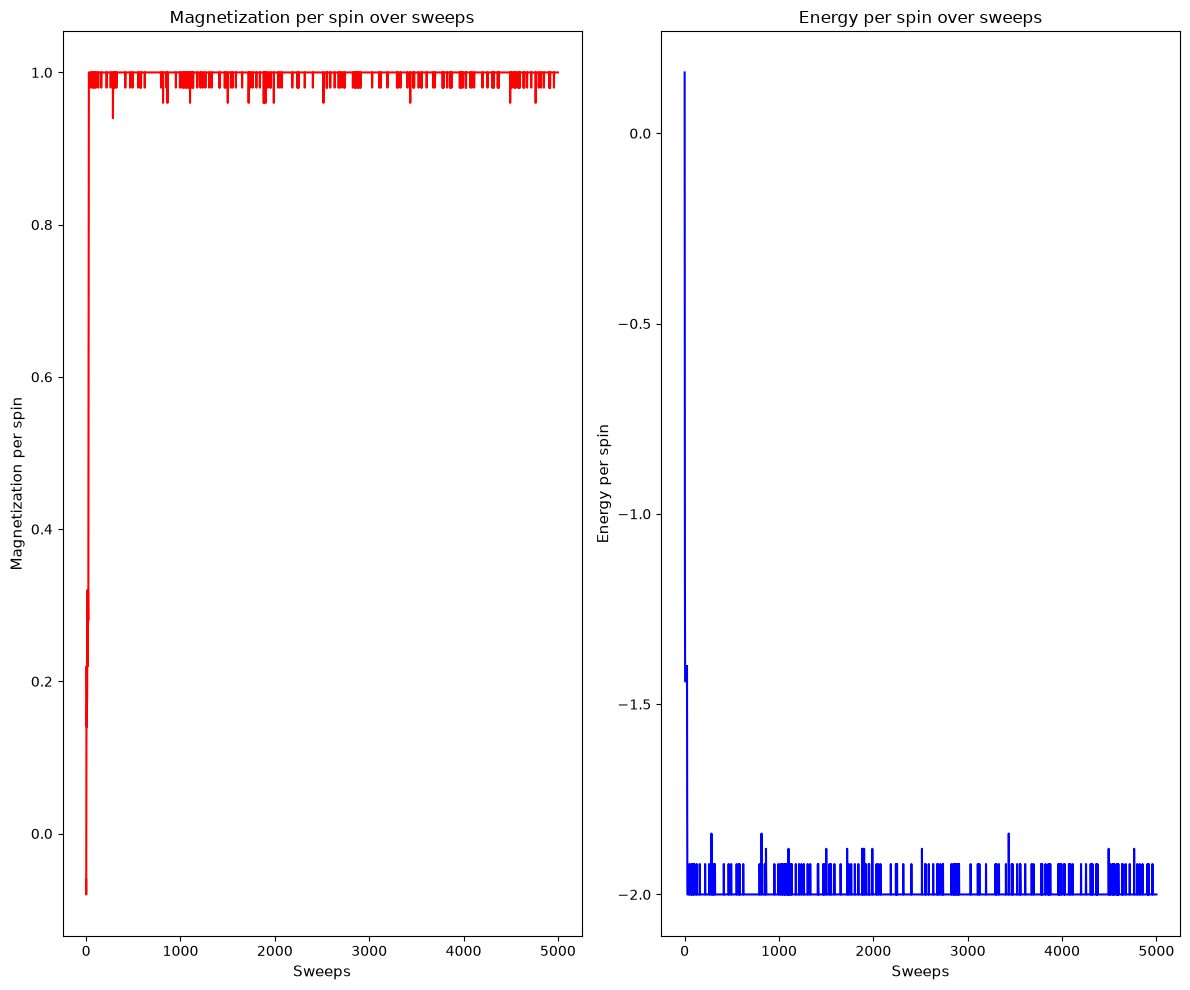

In [ ]:
import numpy as np 
import supporting_function as sf
import matplotlib.pyplot as plt

h = 0 #external magnetic field
J = 1 #interaction energy
k_1 = 1 #Boltzmann constant and it said that J*k_B = 1
T = 1 #temperature
L = 10 #lattice size

s = sf.make_lattice(L, mode = "random") # let s = the array of spins, with each spin being either +1 or -1

print("------- Initial lattice -------")
print(s)
print("\n")

print("------- Starting Monte Carlo sweep -------")
#Monte Carlo Sweep
s, sweep, plots_m, plots_e = sf.run_sweep(s, T, 5000, J, h)

print("\n")
print("------- Final lattice after Monte Carlo sweep -------")
print("\n")
print ("Final lattice after 1 Monte Carlo sweep:\n", s)

E, e = sf.calc_E_e(s)
M, m = sf.calc_M_m(s)

print("\n")
print("------- Final Energy and Magnetism after Monte Carlo sweep -------")
print("\n")
print("Total Energy: ", E)
print("Energy per spin: ", e)
print("Total Magnetism: ", M)
print("Magnetization per spin: ", m)
print("\n")

print("------- c and chi after Monte Carlo sweep -------")



print("------- Plotting Magnetization and Energy per spin vs Sweeps -------")

t = np.arange(len(plots_m))
plt.figure(figsize = (12,10)) 
plt.subplot(1,2,1)
plt.plot(t, plots_m, color="red")

plt.title("Magnetization per spin over sweeps")
plt.xlabel('Sweeps', fontsize=11)
plt.ylabel('Magnetization per spin', fontsize=11)

plt.subplot(1,2,2)
plt.plot(t, plots_e, color="blue")

plt.title("Energy per spin over sweeps")
plt.xlabel('Sweeps', fontsize=11)
plt.ylabel('Energy per spin', fontsize=11)

plt.tight_layout()
plt.show()


In [9]:
import numpy as np 

#variables 

h = 0 #external magnetic field
J = 1 #interaction energy
k_1 = 1 #Boltzmann constant and it said that J*k_B = 1
T = 1 #temperature

L = 10 #lattice length

N= L**2 #total number of spins

#creating lattice of random initial spin

s = sf.make_lattice(10, mode = "random") # let s = the array of spins, with each spin being either +1 or -1
print(s)

for _ in range(L*L):
    r=np.random.randint(L)
    c=np.random.randint(L)

#Monte Carlo Sweep

for r in range(L):
    for c in range(L):
        up = s[(r-1)% L,c] #defining nearest neighbours (modulo L to account for periodic boundary conditions)
        left = s[r, (c-1)% L]
        down = s[(r+1)% L,c]
        right = s[r, (c+1)% L]

        
        nn_sum = (up + left + down + right) # sum of nearest neighbours
        print("nn_sum =", nn_sum)

        E_flip = 2 * J * s[r,c] * nn_sum + 2 * h * s[r,c] #if spin is flipped then energy change = -2E so 2*s*J + 2*s*h but h = 0
        print("E_flip =", E_flip)

        if E_flip < 0: #if energy change is negative then flip the spin
            s[r,c] *= -1
            print("Spin flipped at (",r,",",c,")")

        if E_flip >= 0: #if energy change is positive then flip the spin if it meets a certain probability
            p = np.exp(-E_flip/(k_1*T))
            print("P of flip =", p)
            if np.random.rand() < p:
                s[r,c] *= -1
                print("spin flipped at (",r,",",c,") with probability =", p)

def E(s, J=1.0, h=0.0): #E is total energy
    down = np.roll(s, -1, axis=0)
    right = np.roll(s, -1, axis=1)
    pair_sum = np.sum(s * down) + np.sum(s * right)
    return -J * pair_sum - h * np.sum(s) #back to equation of E
print("E=", E(s, J, h))

def M(s): #M is total magnetization
    return np.sum(s)
print("M=", M(s))

def e(s,J=1.0, h=0.0): #e is energy per spin
    return E(s, J, h)/N
print("e=", e(s, J, h))

def m(s): #m is magnetization per spin
    return np.sum(s)/N
print("m=", m(s))

[[-1  1  1  1  1 -1  1  1  1 -1]
 [ 1  1 -1 -1  1 -1 -1  1 -1  1]
 [ 1 -1 -1  1 -1 -1  1 -1 -1 -1]
 [ 1  1 -1 -1 -1  1 -1  1 -1  1]
 [ 1  1 -1 -1 -1  1  1 -1  1  1]
 [ 1  1  1 -1  1  1  1  1 -1 -1]
 [ 1  1  1  1  1  1  1  1 -1 -1]
 [-1  1 -1  1  1 -1 -1 -1 -1 -1]
 [ 1 -1  1  1  1  1  1  1 -1  1]
 [-1  1  1 -1 -1  1  1 -1 -1  1]]
nn_sum = 0
E_flip = 0
P of flip = 1.0
spin flipped at ( 0 , 0 ) with probability = 1.0
nn_sum = 4
E_flip = 8
P of flip = 0.00033546262790251185
nn_sum = 2
E_flip = 4
P of flip = 0.01831563888873418
nn_sum = 0
E_flip = 0
P of flip = 1.0
spin flipped at ( 0 , 3 ) with probability = 1.0
nn_sum = -2
E_flip = -4
Spin flipped at ( 0 , 4 )
nn_sum = 0
E_flip = 0
P of flip = 1.0
spin flipped at ( 0 , 5 ) with probability = 1.0
nn_sum = 2
E_flip = 4
P of flip = 0.01831563888873418
nn_sum = 2
E_flip = 4
P of flip = 0.01831563888873418
nn_sum = -2
E_flip = -4
Spin flipped at ( 0 , 8 )
nn_sum = 2
E_flip = -4
Spin flipped at ( 0 , 9 )
nn_sum = 4
E_flip = 8
P of flip = 0.0003